In [1]:
import os
import re
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import sklearn.metrics as skm
from google.colab import drive

from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import RobertaModel
from tokenizers import Tokenizer, normalizers, processors
from tokenizers.normalizers import StripAccents, Replace
from tokenizers.processors import TemplateProcessing
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import PreTokenizer
from tokenizers import NormalizedString, PreTokenizedString
from typing import List
from clang import cindex

In [2]:
SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [3]:
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/VulnSight')

DATA_ROOT = PROJECT_ROOT / 'finetune'
MYDATASET = 'reveal'  # e.g. 'devign', 'draper'
TASK = 'function'  # used by D2A
MAX_LENGTH = 1024
BATCH_SIZE = 32

VOCAB_SIZE = 50000
EMBED_SIZE = VOCAB_SIZE + 2
EMBED_DIM = 768

TOKENIZER_VOCAB = PROJECT_ROOT / 'tokenizer' / 'drapgh-vocab.json'
TOKENIZER_MERGES = PROJECT_ROOT / 'tokenizer' / 'drapgh-merges.txt'
ROBERTA_EMBEDDING_PATH = PROJECT_ROOT / 'models' / 'VulSight'

CHECKPOINT_PATH = PROJECT_ROOT / 'models' / f'VulSight-CNN_{MYDATASET}' / 'best_model.tar'

print('Project root exists:', PROJECT_ROOT.exists(), PROJECT_ROOT)
print('Dataset root:', DATA_ROOT)
print('Tokenizer vocab exists:', TOKENIZER_VOCAB.exists())
print('Tokenizer merges exists:', TOKENIZER_MERGES.exists())
print('RoBERTa model directory exists:', ROBERTA_EMBEDDING_PATH.exists())
print('Checkpoint exists:', CHECKPOINT_PATH.exists())

Mounted at /content/drive
Project root exists: True /content/drive/MyDrive/VulnSight
Dataset root: /content/drive/MyDrive/VulnSight/finetune
Tokenizer vocab exists: True
Tokenizer merges exists: True
RoBERTa model directory exists: True
Checkpoint exists: True


In [4]:
class MyTokenizer:
    cidx = cindex.Index.create()

    def clang_split(self, i: int, normalized_string: NormalizedString) -> List[NormalizedString]:
        tokens = []
        tu = self.cidx.parse(
            "tmp.c",
            args=[""],
            unsaved_files=[("tmp.c", str(normalized_string.original))],
            options=0,
        )
        for token in tu.get_tokens(extent=tu.cursor.extent):
            spelling = token.spelling.strip()
            if spelling:
                tokens.append(NormalizedString(spelling))
        return tokens

    def pre_tokenize(self, pretok: PreTokenizedString):
        pretok.split(self.clang_split)

vocab, merges = BPE.read_file(
    vocab=str(TOKENIZER_VOCAB),
    merges=str(TOKENIZER_MERGES),
)
my_tokenizer = Tokenizer(BPE(vocab, merges, unk_token="<unk>"))
my_tokenizer.normalizer = normalizers.Sequence([StripAccents(), Replace(" ", "Ä")])
my_tokenizer.pre_tokenizer = PreTokenizer.custom(MyTokenizer())
my_tokenizer.post_processor = TemplateProcessing(
    single="<s> $A </s>",
    special_tokens=[("<s>", 0), ("<pad>", 1), ("</s>", 2), ("<unk>", 3), ("<mask>", 4)],
)
my_tokenizer.enable_truncation(max_length=MAX_LENGTH)
my_tokenizer.enable_padding(
    direction="right", pad_id=1, pad_type_id=0, pad_token="<pad>"
)
print("Tokenizer loaded.")

Tokenizer loaded.


In [5]:

def replace_colname(df):
    rename_map = {
        "functionSource": "func",
        "code": "func",
        "label": "target",
    }
    return df.rename(columns=rename_map)


def load_test_dataframe(dataset_name):
    if dataset_name == "d2a":
        data_dir = DATA_ROOT / "d2a" / TASK
        test_path = data_dir / f"d2a_lbv1_{TASK}_test.csv"

        if not test_path.exists():
            raise FileNotFoundError(
                f"D2A test file not found: {test_path}"
            )

        df = replace_colname(pd.read_csv(test_path))

    elif dataset_name == "devign":
        data_dir = DATA_ROOT / "devign"
        index_path = data_dir / "test.txt"
        json_path = data_dir / "Devign.json"

        if not index_path.exists() or not json_path.exists():
            raise FileNotFoundError(
                f"Devign test files not found in {data_dir}"
            )

        with open(index_path, "r") as f:
            test_indices = [
                int(line.strip())
                for line in f
                if line.strip()
            ]

        df = replace_colname(
            pd.read_json(json_path).iloc[test_indices].copy()
        )

    else:
        candidates = [
            DATA_ROOT / dataset_name / f"{dataset_name}_test.pkl",
            DATA_ROOT / f"{dataset_name}_test.pkl",
            DATA_ROOT / dataset_name / "test.pkl",
        ]

        pkl_path = next(
            (path for path in candidates if path.exists()),
            None
        )

        if pkl_path is None:
            raise FileNotFoundError(
                "Test pickle not found. Checked:\n"
                + "\n".join(str(p) for p in candidates)
            )

        df = replace_colname(pd.read_pickle(pkl_path))

    if "func" not in df.columns:
        raise KeyError(
            f"Code column missing. Available columns: {list(df.columns)}"
        )

    if "target" not in df.columns:
        if "combine" in df.columns:
            df["target"] = df["combine"]
        else:
            raise KeyError(
                "Expected a target/label column in the test dataset."
            )

    # Remove rows without code or labels
    df = df.dropna(subset=["func", "target"]).copy()
    df["target"] = df["target"].astype(int)

    if not df["target"].isin([0, 1]).all():
        raise ValueError("Expected binary labels 0 and 1.")

    return df.reset_index(drop=True)


test_df = load_test_dataframe(MYDATASET)
labels = test_df["target"].tolist()

print("Test rows:", len(test_df))
print("Columns:", test_df.columns.tolist())
print("Label distribution:")
print(pd.Series(labels).value_counts().sort_index())

Test rows: 2274
Columns: ['hash', 'project', 'size', 'target', 'func']
Label distribution:
0    2044
1     230
Name: count, dtype: int64


In [6]:
def cleaner(code):
    ## Remove code comments
    pat = re.compile(r'(/\*([^*]|(\*+[^*/]))*\*+/)|(//.*)')
    code = re.sub(pat,'',code)
    code = re.sub('\n','',code)
    code = re.sub('\t','',code)
    return(code)


test_df = test_df.copy()
test_df["func"] = test_df["func"].apply(cleaner)

encodings = my_tokenizer.encode_batch(
    test_df["func"].tolist()
)

input_ids = torch.tensor(
    [enc.ids for enc in encodings],
    dtype=torch.long
)
labels_tensor = torch.tensor(labels, dtype=torch.long)


class CodeTestDataset(Dataset):
    def __init__(self, input_ids, labels):
        self.input_ids = input_ids
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.labels[idx]


test_dataset = CodeTestDataset(input_ids, labels_tensor)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Tokenized test samples:", len(test_dataset))
print("Input shape:", tuple(input_ids.shape))
print("Expected sequence length:", MAX_LENGTH)
print("All sequences fixed length:",input_ids.ndim == 2 and input_ids.shape[1] == MAX_LENGTH)

Tokenized test samples: 2274
Input shape: (2274, 1024)
Expected sequence length: 1024
All sequences fixed length: True


In [7]:
class myCNN(nn.Module):
    def __init__(self, EMBED_SIZE, EMBED_DIM):
        super().__init__()
        pretrained_weights = RobertaModel.from_pretrained(
            str(ROBERTA_EMBEDDING_PATH)
        ).embeddings.word_embeddings.weight

        self.embed = nn.Embedding.from_pretrained(
            pretrained_weights,
            freeze=True,
            padding_idx=1,
        )
        self.conv1 = nn.Conv1d(in_channels=EMBED_DIM, out_channels=200, kernel_size=3)
        self.conv2 = nn.Conv1d(in_channels=EMBED_DIM, out_channels=200, kernel_size=4)
        self.conv3 = nn.Conv1d(in_channels=EMBED_DIM, out_channels=200, kernel_size=5)
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(200 * 3, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 2)

    def forward(self, x):
        x = self.embed(x)
        x = x.permute(0, 2, 1)
        x1 = F.relu(self.conv1(x))
        x2 = F.relu(self.conv2(x))
        x3 = F.relu(self.conv3(x))
        x1 = F.max_pool1d(x1, x1.shape[2])
        x2 = F.max_pool1d(x2, x2.shape[2])
        x3 = F.max_pool1d(x3, x3.shape[2])
        x = torch.cat([x1, x2, x3], dim=1).flatten(1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

if not ROBERTA_EMBEDDING_PATH.exists():
    raise FileNotFoundError(
        f"Pretrained RoBERTa directory not found: {ROBERTA_EMBEDDING_PATH}. "
        "Place the pretrained model files there or update ROBERTA_EMBEDDING_PATH."
    )
model = myCNN(EMBED_SIZE, EMBED_DIM).to(device)
print("CNN classifier initialized.")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: /content/drive/MyDrive/VulnSight/models/VulSight
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.decoder.weight    | UNEXPECTED | 
lm_head.decoder.bias      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


CNN classifier initialized.


In [8]:
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH.resolve()}\n"
        "Update CHECKPOINT_PATH to a checkpoint saved by the training notebook."
    )

try:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
except TypeError:  # compatibility with older PyTorch versions
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

state_dict = checkpoint.get("model_state_dict", checkpoint)
# Handle checkpoints saved from nn.DataParallel.
if state_dict and all(k.startswith("module.") for k in state_dict.keys()):
    state_dict = {k[len("module."):]: v for k, v in state_dict.items()}

model.load_state_dict(state_dict)
model.eval()
print("Loaded checkpoint:", CHECKPOINT_PATH)
if isinstance(checkpoint, dict) and "epoch" in checkpoint:
    print("Checkpoint epoch:", checkpoint["epoch"])

Loaded checkpoint: /content/drive/MyDrive/VulnSight/models/VulSight-CNN_reveal/best_model.tar
Checkpoint epoch: 5


In [9]:
all_labels = []
all_predictions = []
all_probabilities = []

model.eval()
with torch.no_grad():
    for batch_input_ids, batch_labels in test_loader:
        batch_input_ids = batch_input_ids.to(device)
        batch_labels = batch_labels.to(device)

        logits = model(batch_input_ids)
        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        all_labels.extend(batch_labels.cpu().numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_probabilities.extend(probabilities[:, 1].cpu().numpy().tolist())

print("Inference complete.")

Inference complete.


In [10]:
# Results are separated by model type and dataset name.
# Example: MyDrive/VulnSight/results/CNN/d2a/evaluation_metrics.csv
MODEL_TYPE = "CNN"
RESULTS_DIR = PROJECT_ROOT / "results" / MODEL_TYPE.upper() / MYDATASET.lower()
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

metrics = {
    "model_type": MODEL_TYPE.upper(),
    "dataset": MYDATASET.lower(),
    "num_samples": len(all_labels),
    "accuracy": skm.accuracy_score(all_labels, all_predictions),
    "precision": skm.precision_score(all_labels, all_predictions, zero_division=0),
    "recall": skm.recall_score(all_labels, all_predictions, zero_division=0),
    "f1_score": skm.f1_score(all_labels, all_predictions, zero_division=0),
    "mcc": skm.matthews_corrcoef(all_labels, all_predictions),
    "roc_auc": skm.roc_auc_score(all_labels, all_probabilities)
        if len(set(all_labels)) == 2 else None,
    "pr_auc": skm.average_precision_score(all_labels, all_probabilities)
        if len(set(all_labels)) == 2 else None,
}

metrics_path = RESULTS_DIR / f"{MYDATASET.lower()}_evaluation_metrics.csv"
metrics_df = pd.DataFrame([metrics])
metrics_df.to_csv(metrics_path, index=False)

print("Saved test metrics to:", metrics_path)
print("\nTest evaluation metrics:")
display(metrics_df)

Saved test metrics to: /content/drive/MyDrive/VulnSight/results/CNN/reveal/reveal_evaluation_metrics.csv

Test evaluation metrics:


,model_type,dataset,num_samples,accuracy,precision,recall,f1_score,mcc,roc_auc,pr_auc
0,CNN,reveal,2274,0.758575,0.265786,0.786957,0.397366,0.35702,0.849881,0.488531


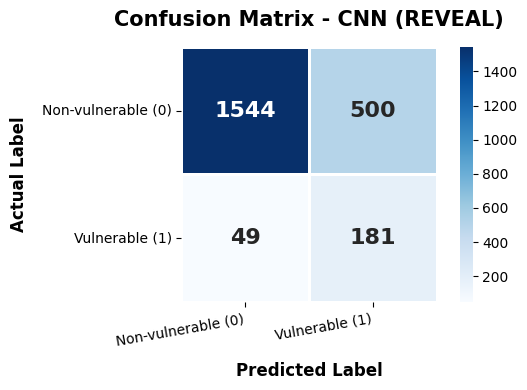


Confusion matrix CSV saved to: /content/drive/MyDrive/VulnSight/results/CNN/reveal/reveal_confusion_matrix.csv
Confusion matrix heatmap saved to: /content/drive/MyDrive/VulnSight/results/CNN/reveal/reveal_confusion_matrix.png


,Non-vulnerable (0),Vulnerable (1)
Non-vulnerable (0),1544,500
Vulnerable (1),49,181


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate confusion matrix
conf_matrix = skm.confusion_matrix(all_labels, all_predictions)

# Create labeled DataFrame
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Non-vulnerable (0)", "Vulnerable (1)"],
    columns=["Non-vulnerable (0)", "Vulnerable (1)"]
)

# Save confusion matrix as CSV
conf_matrix_path = RESULTS_DIR / f"{MYDATASET.lower()}_confusion_matrix.csv"
conf_matrix_df.to_csv(conf_matrix_path, index=True)

# Plot heatmap
plt.figure(figsize=(6, 4))

sns.heatmap(
    conf_matrix_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    cbar=True,
    square=True,
    annot_kws={"size": 16, "weight": "bold"}
)

plt.title(
    f"Confusion Matrix - {MODEL_TYPE.upper()} ({MYDATASET.upper()})",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("Predicted Label", fontsize=12, fontweight="bold", labelpad=10)
plt.ylabel("Actual Label", fontsize=12, fontweight="bold", labelpad=10)

plt.xticks(rotation=10, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()

# Save high-resolution heatmap
heatmap_path = RESULTS_DIR / f"{MYDATASET.lower()}_confusion_matrix.png"
plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nConfusion matrix CSV saved to:", conf_matrix_path)
print("Confusion matrix heatmap saved to:", heatmap_path)

display(conf_matrix_df)